In [1]:
import common as cm
import os
import pandas as pd
import numpy as np

# Disease overlap (Venn)

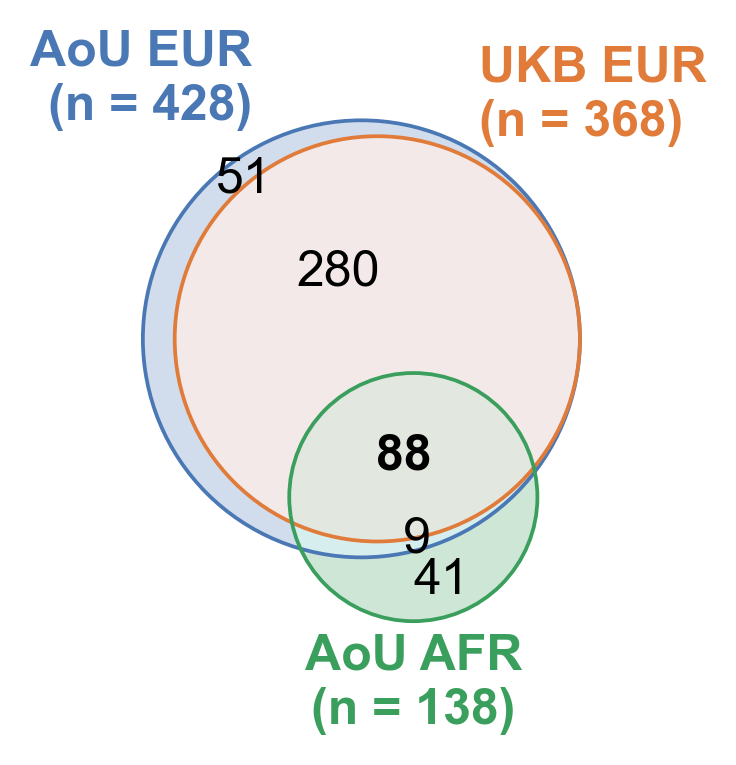

In [2]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib_venn import venn3, venn3_circles

### Publication style: Arial 7 pt, high-res rendering ###
matplotlib.rcParams.update({"font.family": "Arial", "font.size": 7, "pdf.fonttype": 42,
                            "figure.dpi": 300, "savefig.dpi": 600})

### Read three full AUC matrices (rows = target ICD) ###
auc_dir = os.path.join(cm.ROOT_PATH, "result", "auc_landscape")
aou_full_auc_matrix = pd.read_csv(os.path.join(auc_dir, "aou_auc_landscape_full_matrix.csv"), index_col=0)
ukb_full_auc_matrix = pd.read_csv(os.path.join(auc_dir, "ukb_auc_landscape_full_matrix.csv"), index_col=0)
afr_full_auc_matrix = pd.read_csv(os.path.join(auc_dir, "afr_auc_landscape_full_matrix.csv"), index_col=0)

### Target ICD sets ###
aou_set = set(aou_full_auc_matrix.index.astype(str))
ukb_set = set(ukb_full_auc_matrix.index.astype(str))
afr_set = set(afr_full_auc_matrix.index.astype(str))

### Cohort colors: same as Fig 1a schematic (AoU EUR / UKB EUR / AoU AFR) ###
cohort_colors = ("#4A78B5", "#E07B39", "#3A9E5C")

### Area-proportional Venn with light fills ###
fig, ax = plt.subplots(figsize=(2.6, 2.4))
v = venn3(
    subsets=[aou_set, ukb_set, afr_set],
    set_labels=(f"AoU EUR\n(n = {len(aou_set)})", f"UKB EUR\n(n = {len(ukb_set)})", f"AoU AFR\n(n = {len(afr_set)})"),
    set_colors=cohort_colors,
    alpha=0.25,
    ax=ax,
)

# Remove default patch edges; colored outlines are drawn separately below
for patch in v.patches:
    if patch is not None:
        patch.set_edgecolor("none")

# Colored circle outlines with the same (weighted) layout so they align with the fills
circles = venn3_circles(subsets=[aou_set, ukb_set, afr_set], linewidth=0.9, ax=ax)
for c, col in zip(circles, cohort_colors):
    c.set_edgecolor(col)

# Set labels: bold, colored by cohort (doubles as a legend)
for label, col in zip(v.set_labels, cohort_colors):
    if label is not None:
        label.set_fontsize(12)
        label.set_fontweight("bold")
        label.set_color(col)

# Region counts: hide zero regions, bold the three-way core
for region_id in ["100", "010", "001", "110", "101", "011", "111"]:
    lab = v.get_label_by_id(region_id)
    if lab is None:
        continue
    if lab.get_text() == "0":
        lab.set_text("")
    lab.set_fontsize(12)
    if region_id == "111":
        lab.set_fontweight("bold")

### Save vector PDF for the paper and transparent PNG for slides ###
ax.set_axis_off()
plt.tight_layout(pad=0.2)
plt.show()

# Color legend



In [3]:
import matplotlib.patches as mpatches

# Intersect ICD codes across the three cohorts (assumes each is a set of ICD codes)
total_icd_set = aou_set | ukb_set | afr_set

# Map each shared ICD code to its chapter
present_chapters = {cm.assign_chapter(icd) for icd in total_icd_set}

# Keep the canonical chapter order defined in the color map
chapter_order = [ch for ch in cm.chapter2color_map if ch in present_chapters]

# ===== Legend only =====
fig_legend, ax_legend = plt.subplots(figsize=(20, 3), dpi=600)
ax_legend.axis("off")  # Hide the empty axes

# Build chapter color legend handles in canonical order
handles = [
    mpatches.Patch(color=cm.chapter2color_map[ch], label=f"{cm.chapter2roman_map[ch]}: {ch}")
    for ch in chapter_order
]

leg = fig_legend.legend(
    handles=handles,
    title="ICD-10 Chapters",
    loc="center",
    ncol=5,
    frameon=False,      # No box around the legend
    labelspacing=1.0,   # Vertical spacing between rows
    prop={"weight": "bold", "size": 22},
    title_fontproperties={"weight": "bold", "size": 24},
)

# Save only the legend region
plt.show()

# Construct pmatrix and bmatrix

In [4]:
# Read full AUC matrix (rows = target ICD, columns = "<candidate ICD>_<method>")
aou_full_auc_matrix = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "auc_landscape", "aou_auc_landscape_full_matrix.csv"), index_col=0)
cand_disease = aou_full_auc_matrix.columns.str.rsplit("_", n=1).str[0]
aou_pmatrix = aou_full_auc_matrix.T.groupby(cand_disease, sort=False).max().T

# Keep top-10 AUCs per row, set all others (including NaN) to 0
row_rank = aou_pmatrix.rank(axis=1, ascending=False, method="first")
n_top = row_rank.max(axis=1).clip(upper=10)
aou_pmatrix = (row_rank.rsub(n_top + 1, axis=0)).where(row_rank <= 10, 0).fillna(0).astype(int)

# Sanity check: same rows, one column per candidate disease
print(aou_full_auc_matrix.shape, "->", aou_pmatrix.shape)

ukb_full_auc_matrix = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "auc_landscape", "ukb_auc_landscape_full_matrix.csv"), index_col=0)
cand_disease = ukb_full_auc_matrix.columns.str.rsplit("_", n=1).str[0]
ukb_pmatrix = ukb_full_auc_matrix.T.groupby(cand_disease, sort=False).max().T

# Keep top-10 AUCs per row, set all others (including NaN) to 0
row_rank = ukb_pmatrix.rank(axis=1, ascending=False, method="first")
n_top = row_rank.max(axis=1).clip(upper=10)
ukb_pmatrix = (row_rank.rsub(n_top + 1, axis=0)).where(row_rank <= 10, 0).fillna(0).astype(int)

# Sanity check: same rows, one column per candidate disease
print(ukb_full_auc_matrix.shape, "->", ukb_pmatrix.shape)

afr_full_auc_matrix = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "auc_landscape", "afr_auc_landscape_full_matrix.csv"), index_col=0)
cand_disease = afr_full_auc_matrix.columns.str.rsplit("_", n=1).str[0]
afr_pmatrix = afr_full_auc_matrix.T.groupby(cand_disease, sort=False).max().T

# Keep top-10 AUCs per row, set all others (including NaN) to 0
row_rank = afr_pmatrix.rank(axis=1, ascending=False, method="first")
n_top = row_rank.max(axis=1).clip(upper=10)
afr_pmatrix = (row_rank.rsub(n_top + 1, axis=0)).where(row_rank <= 10, 0).fillna(0).astype(int)

# Sanity check: same rows, one column per candidate disease
print(afr_full_auc_matrix.shape, "->", afr_pmatrix.shape)

(428, 1280) -> (428, 428)
(368, 1101) -> (368, 368)
(138, 414) -> (138, 138)


In [5]:
aou_bmatrix = (aou_pmatrix > 0).astype(int)
ukb_bmatrix = (ukb_pmatrix > 0).astype(int)
afr_bmatrix = (afr_pmatrix > 0).astype(int)

In [6]:
# Sort row and columns by ICD code
roman_to_idx = {roman: idx for idx, roman in enumerate(cm.roman_numerals)}

# aou_pmatrix
row_meta = pd.DataFrame({"icd": aou_pmatrix.index})
row_meta["chapter"] = row_meta["icd"].apply(cm.assign_chapter)
row_meta["roman"] = row_meta["chapter"].map(cm.chapter2roman_map)
row_meta["roman_index"] = row_meta["roman"].map(roman_to_idx)

col_meta = pd.DataFrame({"icd": aou_pmatrix.columns})
col_meta["chapter"] = col_meta["icd"].apply(cm.assign_chapter)
col_meta["roman"] = col_meta["chapter"].map(cm.chapter2roman_map)
col_meta["roman_index"] = col_meta["roman"].map(roman_to_idx)

row_meta = row_meta.sort_values(["roman_index", "icd"], ascending=[True, True]).reset_index(drop=True)
col_meta = col_meta.sort_values(["roman_index", "icd"], ascending=[True, True]).reset_index(drop=True)

aou_pmatrix = aou_pmatrix.loc[row_meta["icd"], col_meta["icd"]]

# ukb_pmatrix
row_meta = pd.DataFrame({"icd": ukb_pmatrix.index})
row_meta["chapter"] = row_meta["icd"].apply(cm.assign_chapter)
row_meta["roman"] = row_meta["chapter"].map(cm.chapter2roman_map)
row_meta["roman_index"] = row_meta["roman"].map(roman_to_idx)

col_meta = pd.DataFrame({"icd": ukb_pmatrix.columns})
col_meta["chapter"] = col_meta["icd"].apply(cm.assign_chapter)
col_meta["roman"] = col_meta["chapter"].map(cm.chapter2roman_map)
col_meta["roman_index"] = col_meta["roman"].map(roman_to_idx)

row_meta = row_meta.sort_values(["roman_index", "icd"], ascending=[True, True]).reset_index(drop=True)
col_meta = col_meta.sort_values(["roman_index", "icd"], ascending=[True, True]).reset_index(drop=True)

ukb_pmatrix = ukb_pmatrix.loc[row_meta["icd"], col_meta["icd"]]

# afr_pmatrix
row_meta = pd.DataFrame({"icd": afr_pmatrix.index})
row_meta["chapter"] = row_meta["icd"].apply(cm.assign_chapter)
row_meta["roman"] = row_meta["chapter"].map(cm.chapter2roman_map)
row_meta["roman_index"] = row_meta["roman"].map(roman_to_idx)

col_meta = pd.DataFrame({"icd": afr_pmatrix.columns})
col_meta["chapter"] = col_meta["icd"].apply(cm.assign_chapter)
col_meta["roman"] = col_meta["chapter"].map(cm.chapter2roman_map)
col_meta["roman_index"] = col_meta["roman"].map(roman_to_idx)

row_meta = row_meta.sort_values(["roman_index", "icd"], ascending=[True, True]).reset_index(drop=True)
col_meta = col_meta.sort_values(["roman_index", "icd"], ascending=[True, True]).reset_index(drop=True)

afr_pmatrix = afr_pmatrix.loc[row_meta["icd"], col_meta["icd"]]

# Within-PRS distribution

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Input files and colors (colors matched to Fig 1: AoU EUR blue, UKB EUR orange, AoU AFR green)
cohort_files = {
    "AoU EUR": "aou_auc_landscape_full_matrix.csv",
    "UKB EUR": "ukb_auc_landscape_full_matrix.csv",
    "AoU AFR": "afr_auc_landscape_full_matrix.csv",
}
cohort_colors = {"AoU EUR": "#4472C4", "UKB EUR": "#ED7D31", "AoU AFR": "#3BA55C"}

# Rank bins for the own-disease PRS
rank_bins = [0, 1, 5, 10, np.inf]
rank_labels = ["1", "2–5", "6–10", ">10"]

own_rank_list = []

for cohort, fname in cohort_files.items():
    # Read full AUC matrix (rows = target ICD, columns = "<candidate ICD>_<method>")
    full_auc = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "auc_landscape", fname), index_col=0)

    # Collapse the three methods to one column per candidate disease (best AUC), WITHOUT top-10 truncation
    cand_disease = full_auc.columns.str.rsplit("_", n=1).str[0]
    disease_auc = full_auc.T.groupby(cand_disease, sort=False).max().T

    # Rank all candidate diseases within each target (1 = highest AUC); ties share the best rank
    full_rank = disease_auc.rank(axis=1, ascending=False, method="min")

    # Targets whose own disease is also a candidate PRS in the library
    shared = disease_auc.index.intersection(disease_auc.columns)
    print(cohort, "| targets:", disease_auc.shape[0], "| with own PRS:", len(shared))

    # Extract the rank of each target's own-disease PRS (diagonal of the rank matrix)
    own_rank = pd.Series({d: full_rank.at[d, d] for d in shared}, name="own_rank").dropna()
    print(cohort, "| own PRS missing AUC:", len(shared) - len(own_rank))

    # Store long-format records for plotting and reporting
    own_rank_list.append(pd.DataFrame({"cohort": cohort, "target": own_rank.index, "own_rank": own_rank.values}))

# Combine all cohorts
own_rank_df = pd.concat(own_rank_list, ignore_index=True)
own_rank_df["rank_bin"] = pd.cut(own_rank_df["own_rank"], bins=rank_bins, labels=rank_labels)

# Percentage of targets in each rank bin, per cohort
own_rank_pct = (
    own_rank_df.groupby("cohort")["rank_bin"]
    .value_counts(normalize=True)
    .mul(100)
    .unstack()
    .reindex(index=list(cohort_files), columns=rank_labels)
    .fillna(0)
)
print(own_rank_pct.round(1))

# Summary numbers for the main text
print(own_rank_df.groupby("cohort")["own_rank"].agg(
    n="size",
    pct_rank1=lambda x: 100 * (x == 1).mean(),
    pct_top10=lambda x: 100 * (x <= 10).mean(),
    median_rank="median",
).round(1))


AoU EUR | targets: 428 | with own PRS: 428
AoU EUR | own PRS missing AUC: 0
UKB EUR | targets: 368 | with own PRS: 368
UKB EUR | own PRS missing AUC: 0
AoU AFR | targets: 138 | with own PRS: 138
AoU AFR | own PRS missing AUC: 0
rank_bin     1   2–5  6–10   >10
cohort                          
AoU EUR   23.4  18.5   8.6  49.5
UKB EUR   29.3  22.6   7.6  40.5
AoU AFR   32.6  18.1   8.0  41.3
           n  pct_rank1  pct_top10  median_rank
cohort                                         
AoU AFR  138       32.6       58.7          5.0
AoU EUR  428       23.4       50.5         10.0
UKB EUR  368       29.3       59.5          5.0


In [8]:
# Merge own-PRS AUC to judge whether the ranking is informative
own_auc_list = []
for cohort, fname in cohort_files.items():
    # Re-read and collapse to disease-level AUC
    full_auc = pd.read_csv(os.path.join(cm.ROOT_PATH, "result", "auc_landscape", fname), index_col=0)
    cand_disease = full_auc.columns.str.rsplit("_", n=1).str[0]
    disease_auc = full_auc.T.groupby(cand_disease, sort=False).max().T
    shared = disease_auc.index.intersection(disease_auc.columns)
    # Own-disease AUC (diagonal)
    own_auc_list.append(pd.DataFrame({"cohort": cohort, "target": shared,
                                      "own_auc": [disease_auc.at[d, d] for d in shared]}))

own_rank_df = own_rank_df.merge(pd.concat(own_auc_list), on=["cohort", "target"], how="left")

# Stratify by own-PRS AUC: near-chance vs informative
own_rank_df["auc_group"] = pd.cut(own_rank_df["own_auc"], bins=[0, 0.52, 0.55, 1],
                                  labels=["≤0.52", "0.52–0.55", ">0.55"])

# Percentage of rank-1 and top-10 within each stratum
print(own_rank_df.groupby(["cohort", "auc_group"])["own_rank"].agg(
    n="size",
    pct_rank1=lambda x: 100 * (x == 1).mean(),
    pct_top10=lambda x: 100 * (x <= 10).mean(),
).round(1))

                     n  pct_rank1  pct_top10
cohort  auc_group                           
AoU AFR ≤0.52       73        5.5       28.8
        0.52–0.55   52       55.8       90.4
        >0.55       13       92.3      100.0
AoU EUR ≤0.52      200        1.5       17.5
        0.52–0.55  150       28.0       70.7
        >0.55       78       70.5       96.2
UKB EUR ≤0.52      146        0.7       13.7
        0.52–0.55  128       27.3       82.0
        >0.55       94       76.6      100.0


C:\Users\Jiyao Zhang\AppData\Local\Temp\ipykernel_2468\3706126691.py:20: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(own_rank_df.groupby(["cohort", "auc_group"])["own_rank"].agg(


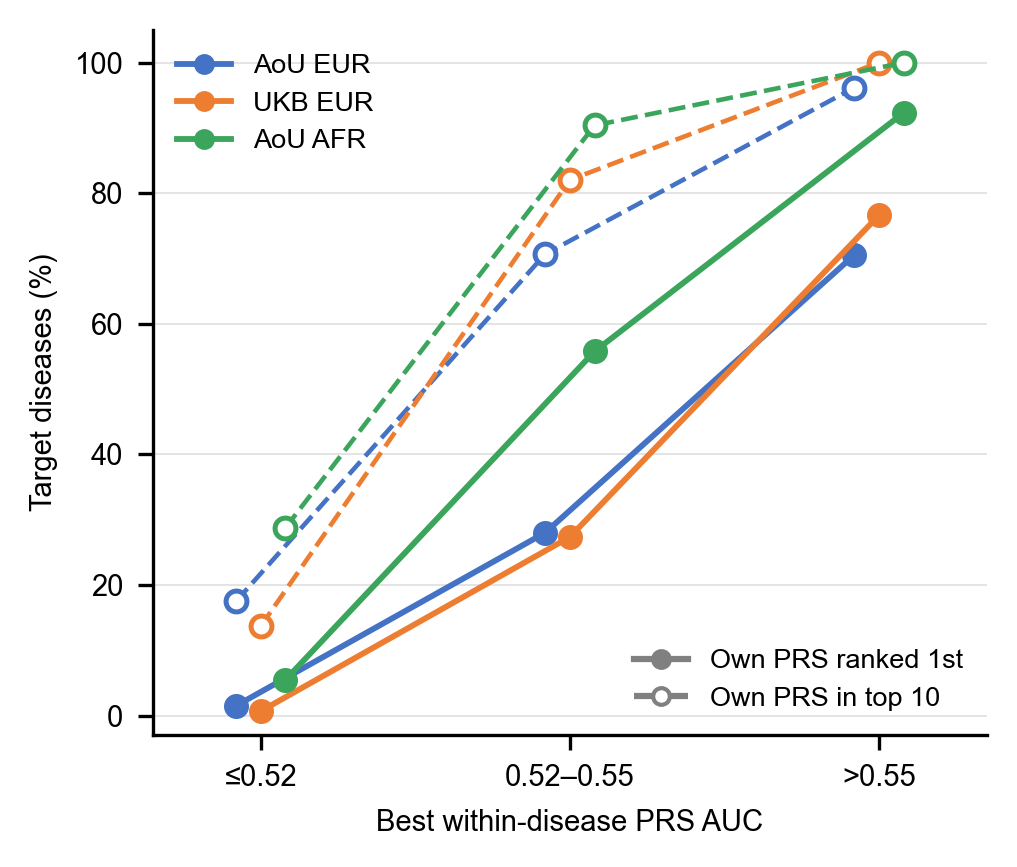

In [9]:
# Rank bins collapsed to three levels for the stacked view
own_rank_df["rank_level"] = pd.cut(own_rank_df["own_rank"], bins=[0, 1, 10, np.inf],
                                   labels=["Rank 1", "Rank 2–10", "Rank >10"])

# Percentage of each rank level within cohort x AUC stratum
stack_pct = (
    own_rank_df.groupby(["auc_group", "cohort"], observed=True)["rank_level"]
    .value_counts(normalize=True).mul(100).unstack().fillna(0)
)
stack_n = own_rank_df.groupby(["auc_group", "cohort"], observed=True).size()

# Order: strata on the outer level, cohorts within each stratum
# Summary percentages per cohort x AUC stratum
strata = ["≤0.52", "0.52–0.55", ">0.55"]
summary = (
    own_rank_df.groupby(["cohort", "auc_group"], observed=True)["own_rank"]
    .agg(pct_rank1=lambda x: 100 * (x == 1).mean(),
         pct_top10=lambda x: 100 * (x <= 10).mean(),
         n="size")
    .reset_index()
)

fig, ax = plt.subplots(figsize=(3.4, 2.9))
x = np.arange(len(strata))

# Small horizontal offset so cohorts do not overlap
offsets = {"AoU EUR": -0.08, "UKB EUR": 0.0, "AoU AFR": 0.08}

for cohort in cohort_files:
    # Data for this cohort in stratum order
    d = summary[summary["cohort"] == cohort].set_index("auc_group").reindex(strata)
    xc = x + offsets[cohort]
    col = cohort_colors[cohort]

    # Top-10 rate: dashed line with open markers
    ax.plot(xc, d["pct_top10"], ls="--", lw=1.1, color=col, marker="o",
            mfc="white", mec=col, ms=5, mew=1.2)

    # Rank-1 rate: solid line with filled markers
    ax.plot(xc, d["pct_rank1"], ls="-", lw=1.4, color=col, marker="o",
            mfc=col, mec=col, ms=5, label=cohort)

# Axis formatting
ax.set_xticks(x)
ax.set_xticklabels(strata)
ax.set_xlim(-0.35, len(strata) - 0.65)
ax.set_ylim(-3, 105)
ax.set_xlabel("Best within-disease PRS AUC")
ax.set_ylabel("Target diseases (%)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", lw=0.4, alpha=0.4)

# Legend 1: cohorts (colors)
leg1 = ax.legend(frameon=False, fontsize=6.5, loc="upper left", markerscale=0.8)
ax.add_artist(leg1)

# Legend 2: metrics (marker style)
from matplotlib.lines import Line2D
metric_handles = [
    Line2D([0], [0], color="grey", ls="-", marker="o", mfc="grey", ms=4, label="Own PRS ranked 1st"),
    Line2D([0], [0], color="grey", ls="--", marker="o", mfc="white", ms=4, label="Own PRS in top 10"),
]
ax.legend(handles=metric_handles, frameon=False, fontsize=6.5, loc="lower right")

plt.tight_layout()
plt.show()

# Heatmap

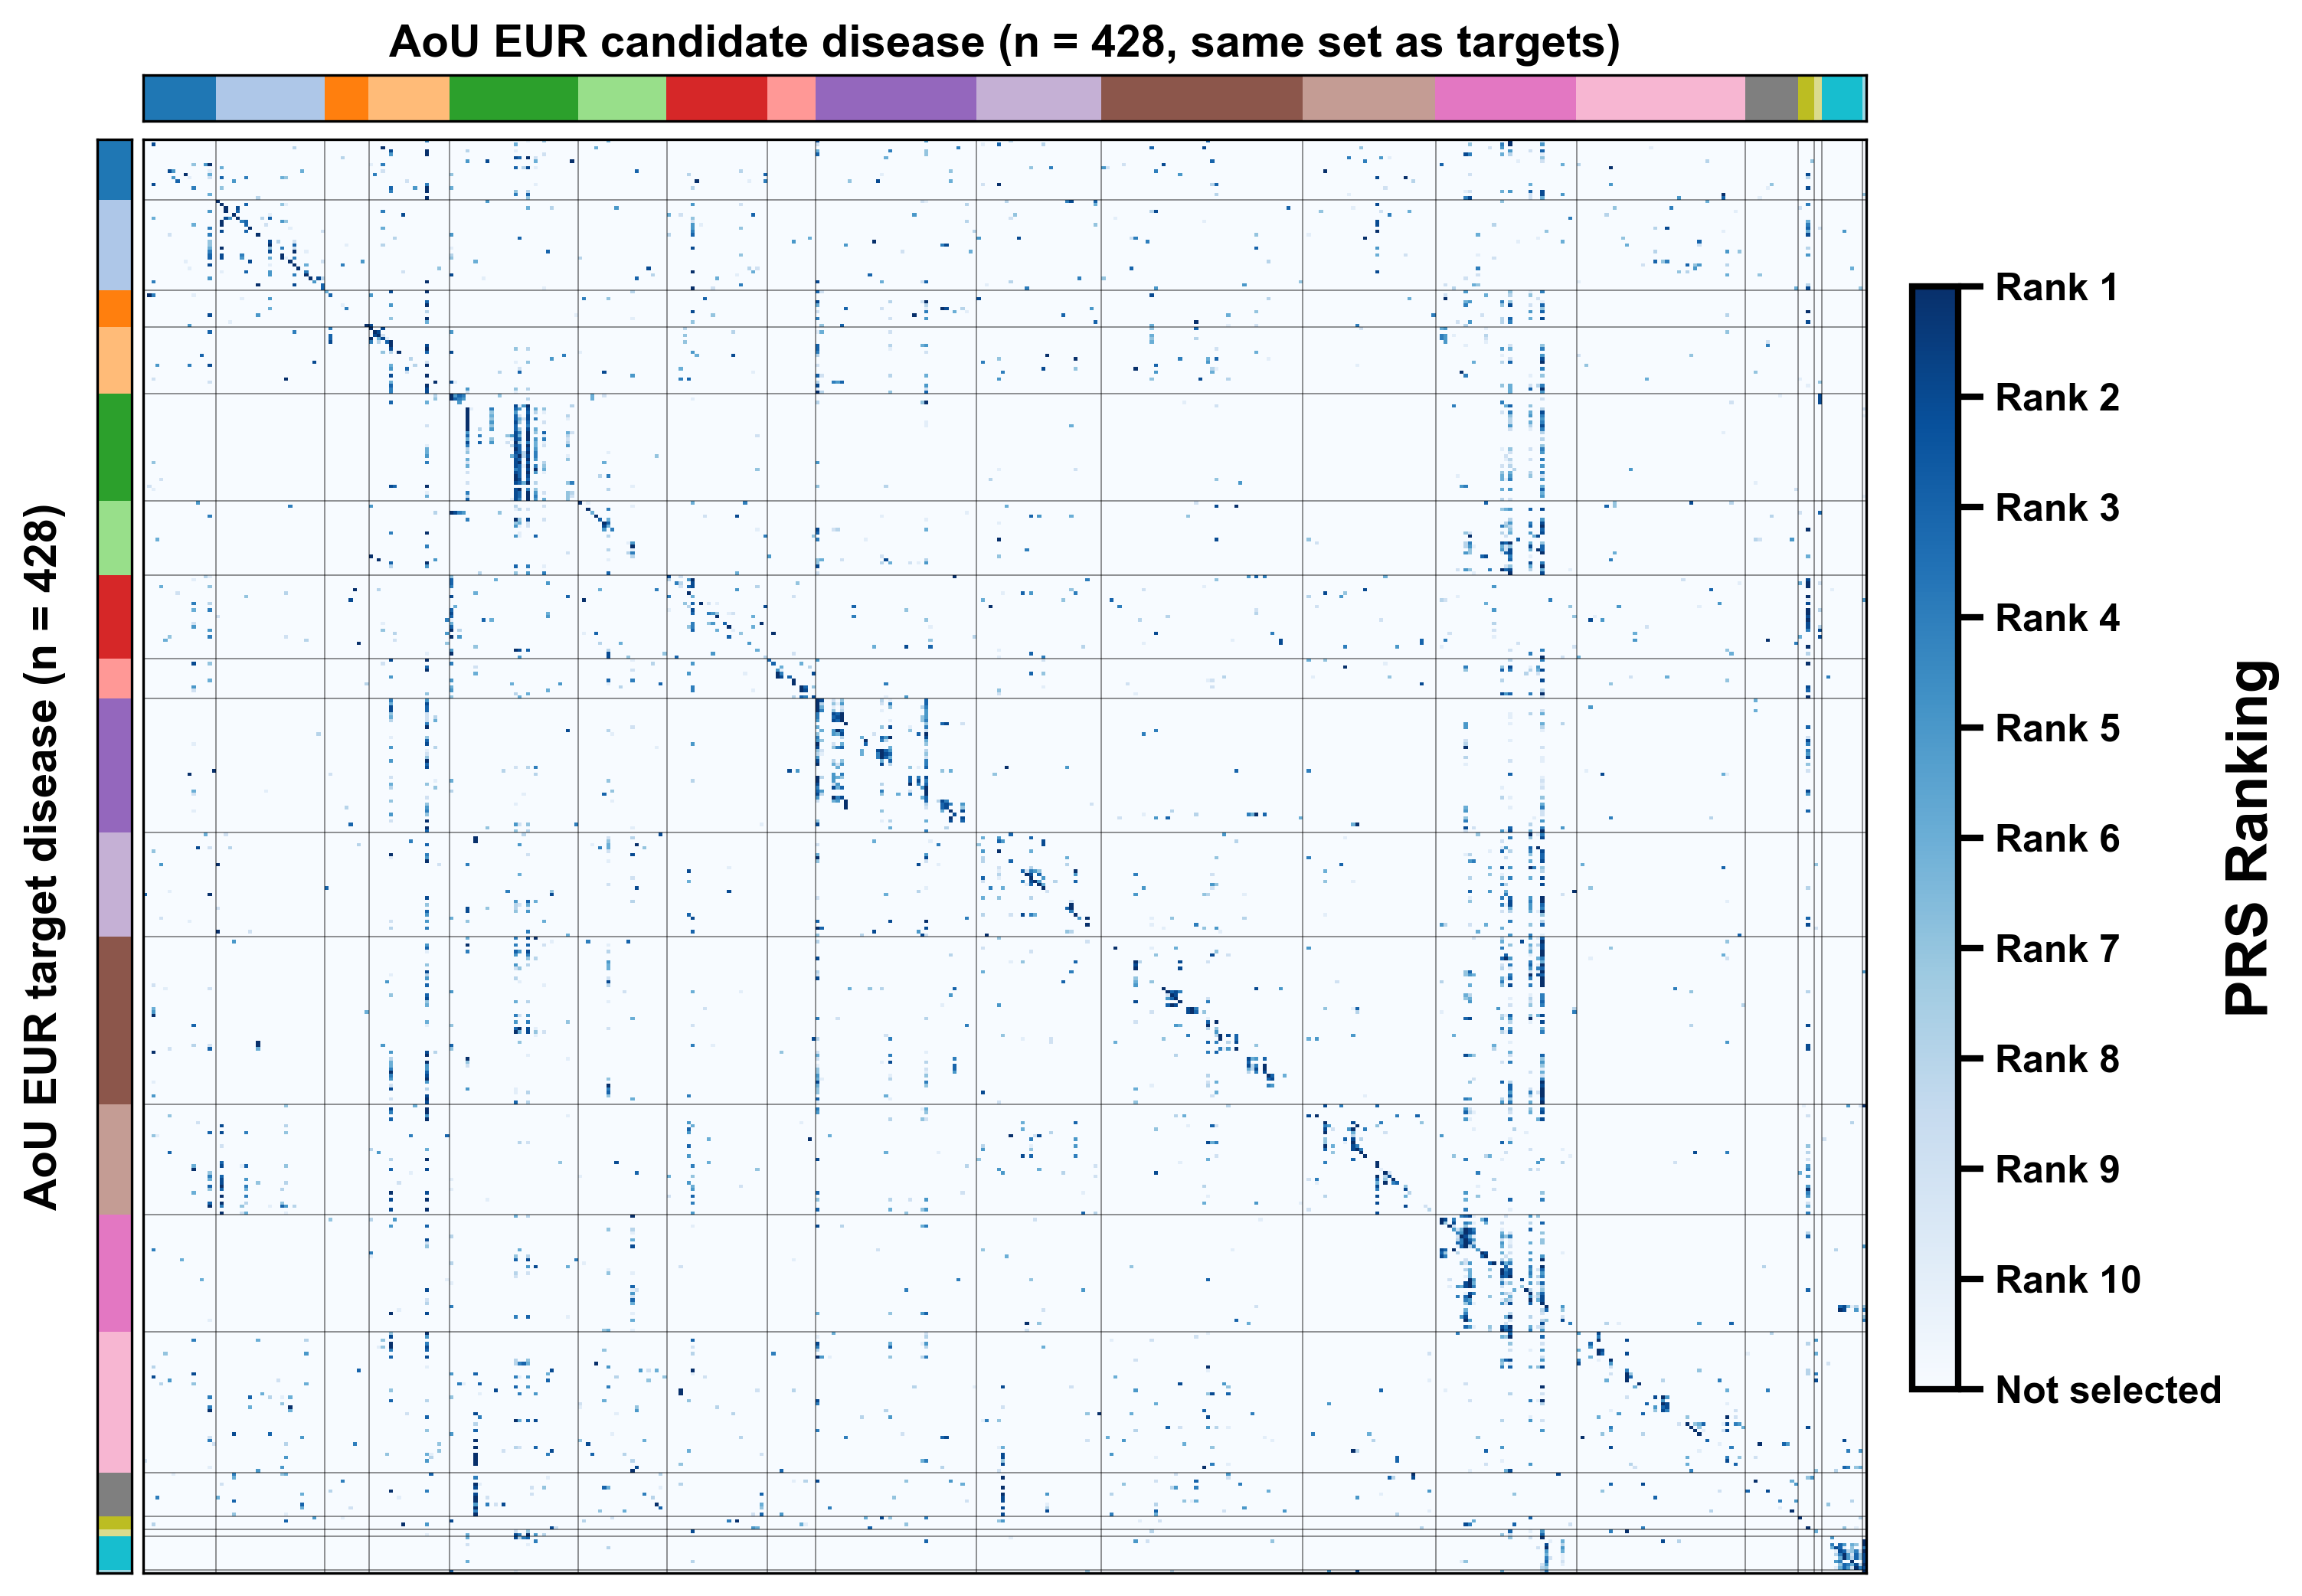

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import matplotlib
import seaborn as sns

matplotlib.rcParams["font.family"] = "Arial"

row_icd = list(aou_pmatrix.index)
col_icd = list(aou_pmatrix.columns)

row_chapters = [cm.assign_chapter(icd) for icd in row_icd]
col_chapters = [cm.assign_chapter(icd) for icd in col_icd]

row_colors = [cm.chapter2color_map.get(ch) for ch in row_chapters]
col_colors = [cm.chapter2color_map.get(ch) for ch in col_chapters]

# Figure layout
fig = plt.figure(figsize=(10, 8))

ax_colstrip = fig.add_axes([0.09, 0.91, 0.75, 0.025])
ax_rowstrip = fig.add_axes([0.07, 0.12, 0.015, 0.78])
ax_hm       = fig.add_axes([0.09, 0.12, 0.75, 0.78])
ax_cbar     = fig.add_axes([0.86, 0.22, 0.02, 0.60])

# Row chapter color strip
row_strip_array = np.array([mcolors.to_rgba(c) for c in row_colors]).reshape(len(row_icd), 1, 4)
ax_rowstrip.imshow(row_strip_array, aspect="auto", origin="upper")

ax_rowstrip.set_xticks([])
ax_rowstrip.set_yticks([])
ax_rowstrip.set_ylabel(f"AoU EUR target disease (n = {len(row_icd)})", fontsize=14, fontweight="bold", labelpad=10)

# Column chapter color strip
col_strip_array = np.array([mcolors.to_rgba(c) for c in col_colors]).reshape(1, len(col_icd), 4)
ax_colstrip.imshow(col_strip_array, aspect="auto", origin="upper")

ax_colstrip.set_xticks([])
ax_colstrip.set_yticks([])
ax_colstrip.set_title(f"AoU EUR candidate disease (n = {len(col_icd)}, same set as targets)", fontsize=14, fontweight="bold", pad=6)

# Heatmap
sns.heatmap(aou_pmatrix, cmap="Blues", vmin=0, vmax=10, ax=ax_hm, xticklabels=False, yticklabels=False, cbar=False)
ax_hm.set_xlabel("")
ax_hm.set_ylabel("")

for _, spine in ax_hm.spines.items():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

# Chapter boundaries
row_boundaries = [i for i in range(1, len(row_chapters)) if row_chapters[i] != row_chapters[i - 1]]
col_boundaries = [i for i in range(1, len(col_chapters)) if col_chapters[i] != col_chapters[i - 1]]

for b in row_boundaries:
    ax_hm.axhline(b, color="black", linewidth=0.4, alpha=0.5)

for b in col_boundaries:
    ax_hm.axvline(b, color="black", linewidth=0.4, alpha=0.5)

# Colorbar
sm = plt.cm.ScalarMappable(cmap="Blues", norm=plt.Normalize(vmin=0, vmax=10))
sm.set_array([])

cbar = fig.colorbar(sm, cax=ax_cbar, ticks=list(range(11)))
cbar.set_ticklabels(["Not selected"] + [f"Rank {11 - v}" for v in range(1, 11)])
cbar.set_label("PRS Ranking", fontsize=18, fontweight="bold", labelpad=1)
cbar.outline.set_linewidth(2)
cbar.ax.tick_params(width=2, length=8)

for spine in cbar.ax.spines.values():
    spine.set_linewidth(2)
for label in cbar.ax.get_yticklabels():
    label.set_fontweight("bold")
    label.set_fontsize(12)

plt.show()

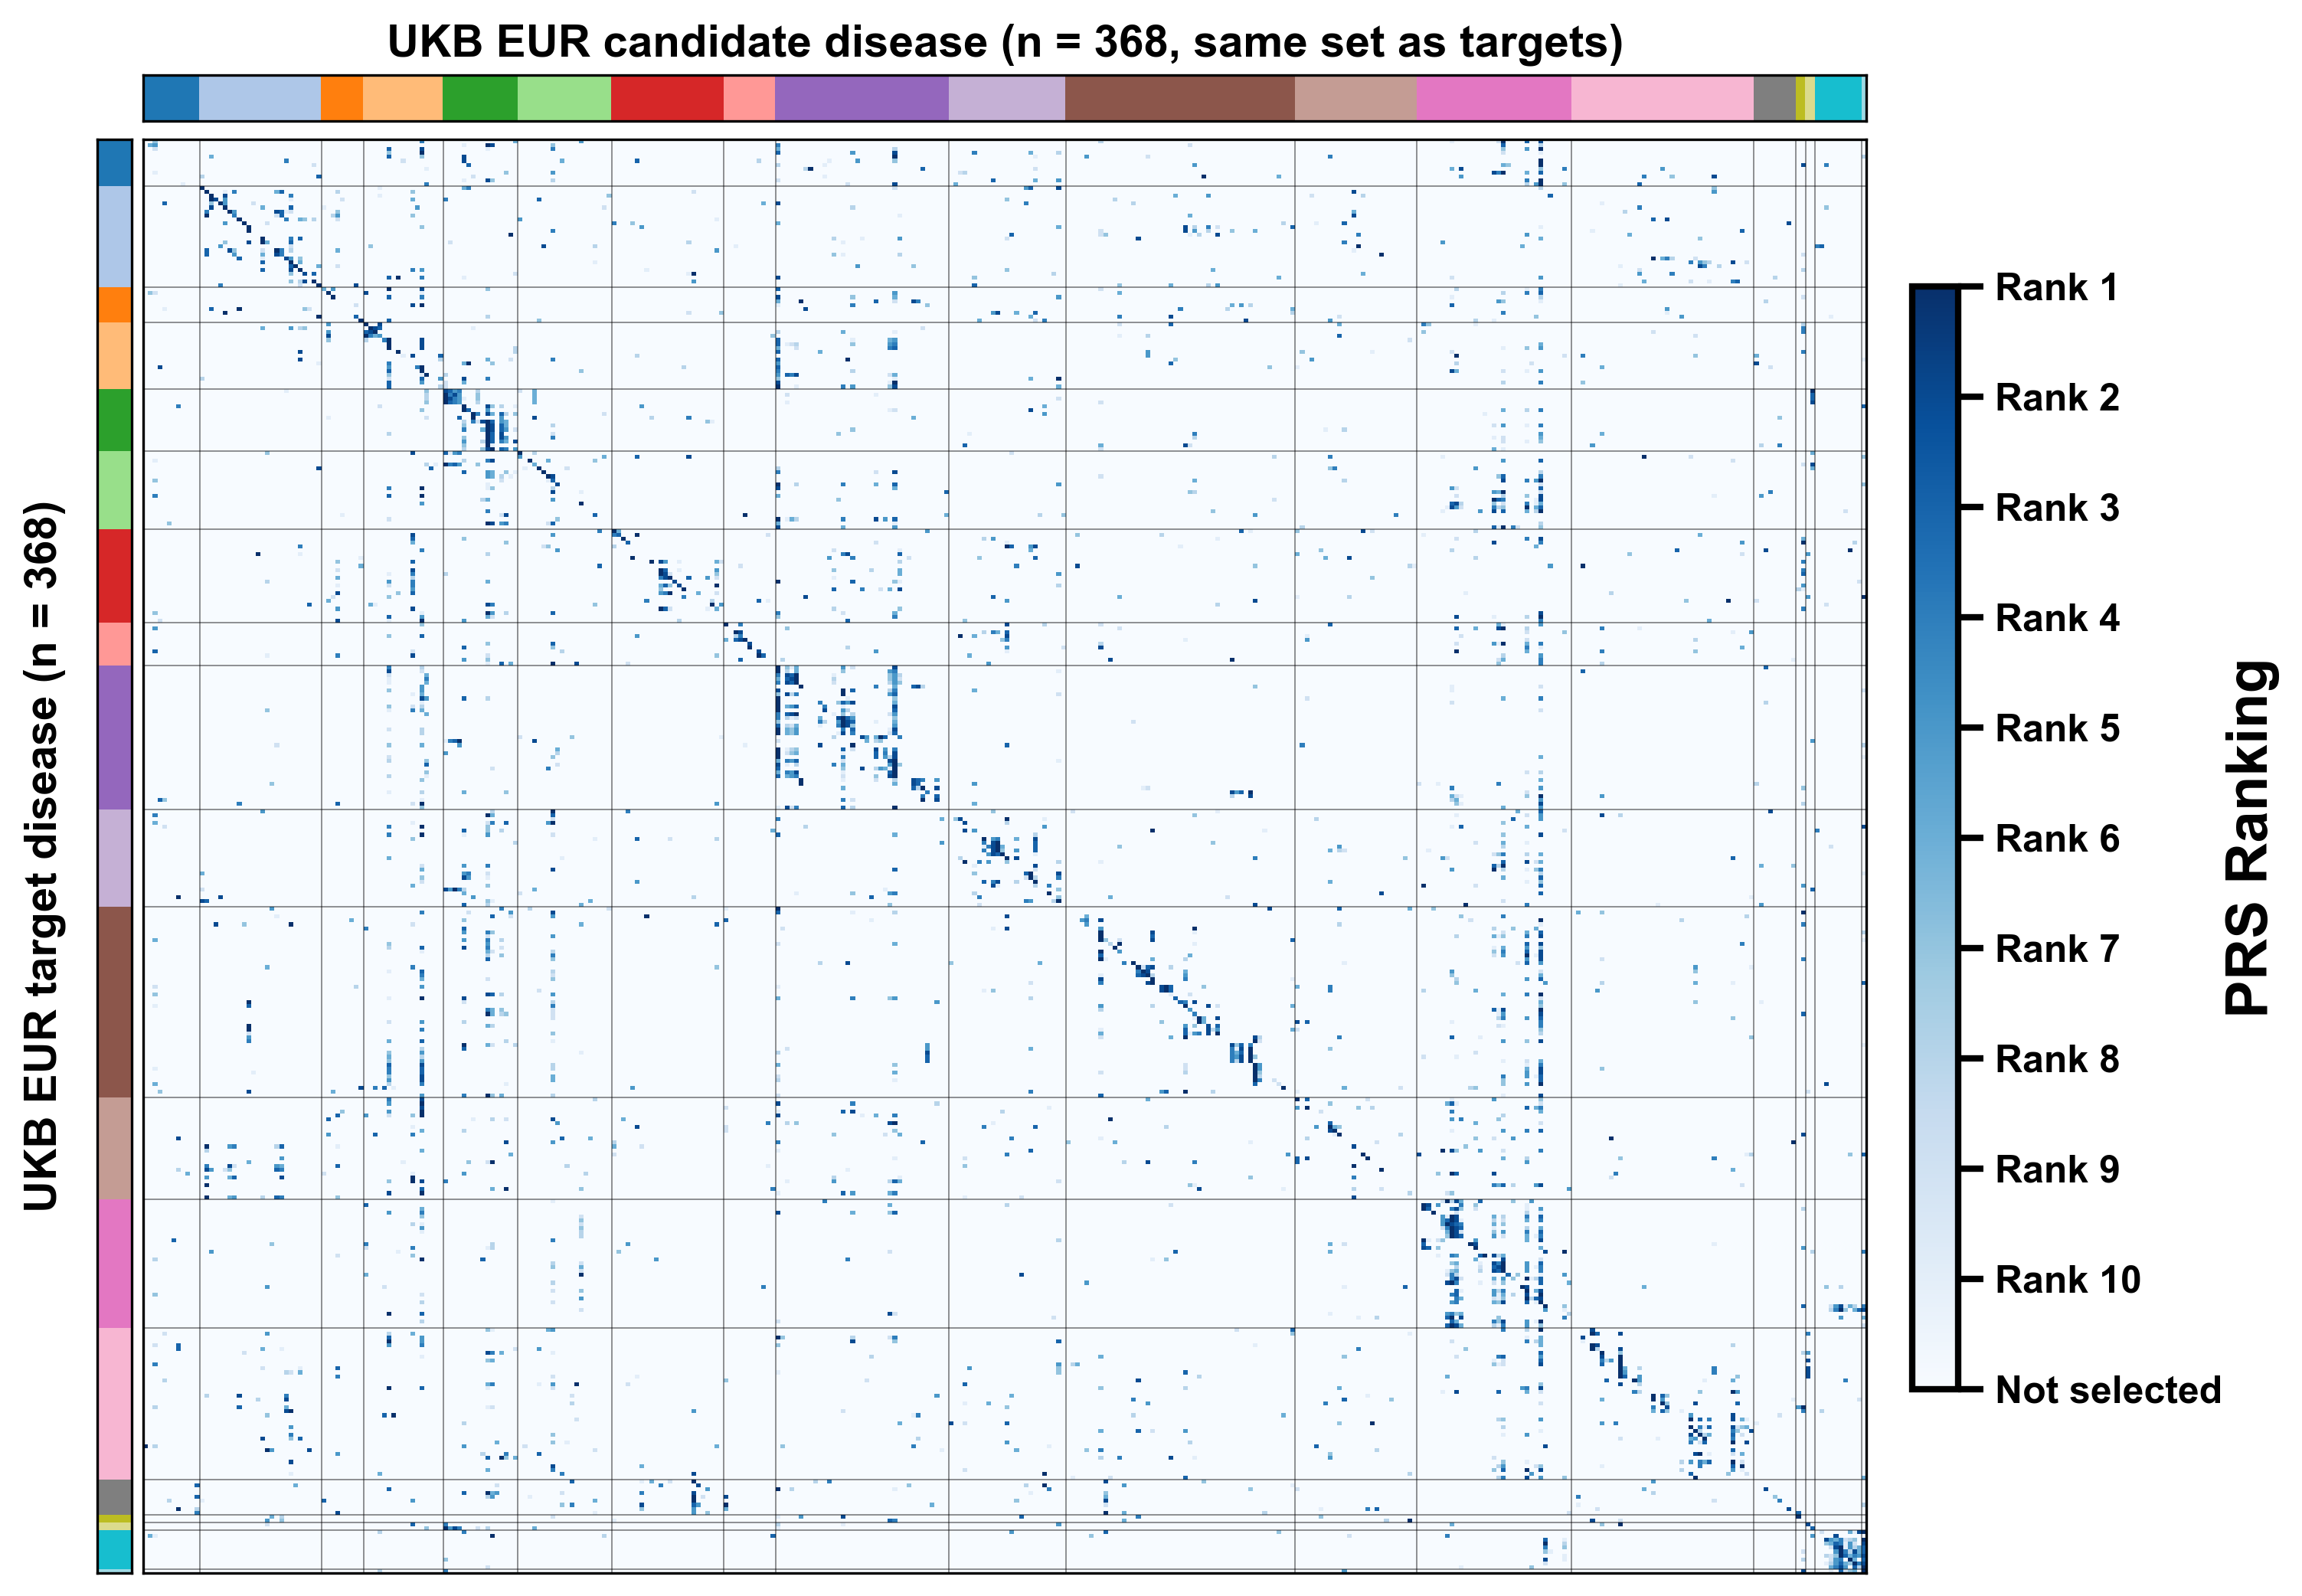

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import matplotlib
import seaborn as sns

matplotlib.rcParams["font.family"] = "Arial"

row_icd = list(ukb_pmatrix.index)
col_icd = list(ukb_pmatrix.columns)

row_chapters = [cm.assign_chapter(icd) for icd in row_icd]
col_chapters = [cm.assign_chapter(icd) for icd in col_icd]

row_colors = [cm.chapter2color_map.get(ch) for ch in row_chapters]
col_colors = [cm.chapter2color_map.get(ch) for ch in col_chapters]

# Figure layout
fig = plt.figure(figsize=(10, 8))

ax_colstrip = fig.add_axes([0.09, 0.91, 0.75, 0.025])
ax_rowstrip = fig.add_axes([0.07, 0.12, 0.015, 0.78])
ax_hm       = fig.add_axes([0.09, 0.12, 0.75, 0.78])
ax_cbar     = fig.add_axes([0.86, 0.22, 0.02, 0.60])

# Row chapter color strip
row_strip_array = np.array([mcolors.to_rgba(c) for c in row_colors]).reshape(len(row_icd), 1, 4)
ax_rowstrip.imshow(row_strip_array, aspect="auto", origin="upper")

ax_rowstrip.set_xticks([])
ax_rowstrip.set_yticks([])
ax_rowstrip.set_ylabel(f"UKB EUR target disease (n = {len(row_icd)})", fontsize=14, fontweight="bold", labelpad=10)

# Column chapter color strip
col_strip_array = np.array([mcolors.to_rgba(c) for c in col_colors]).reshape(1, len(col_icd), 4)
ax_colstrip.imshow(col_strip_array, aspect="auto", origin="upper")

ax_colstrip.set_xticks([])
ax_colstrip.set_yticks([])
ax_colstrip.set_title(f"UKB EUR candidate disease (n = {len(col_icd)}, same set as targets)", fontsize=14, fontweight="bold", pad=6)

# Heatmap
sns.heatmap(ukb_pmatrix, cmap="Blues", vmin=0, vmax=10, ax=ax_hm, xticklabels=False, yticklabels=False, cbar=False)
ax_hm.set_xlabel("")
ax_hm.set_ylabel("")

for _, spine in ax_hm.spines.items():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

# Chapter boundaries
row_boundaries = [i for i in range(1, len(row_chapters)) if row_chapters[i] != row_chapters[i - 1]]
col_boundaries = [i for i in range(1, len(col_chapters)) if col_chapters[i] != col_chapters[i - 1]]

for b in row_boundaries:
    ax_hm.axhline(b, color="black", linewidth=0.4, alpha=0.5)

for b in col_boundaries:
    ax_hm.axvline(b, color="black", linewidth=0.4, alpha=0.5)

# Colorbar
sm = plt.cm.ScalarMappable(cmap="Blues", norm=plt.Normalize(vmin=0, vmax=10))
sm.set_array([])

cbar = fig.colorbar(sm, cax=ax_cbar, ticks=list(range(11)))
cbar.set_ticklabels(["Not selected"] + [f"Rank {11 - v}" for v in range(1, 11)])
cbar.set_label("PRS Ranking", fontsize=18, fontweight="bold", labelpad=1)
cbar.outline.set_linewidth(2)
cbar.ax.tick_params(width=2, length=8)

for spine in cbar.ax.spines.values():
    spine.set_linewidth(2)
for label in cbar.ax.get_yticklabels():
    label.set_fontweight("bold")
    label.set_fontsize(12)

plt.show()

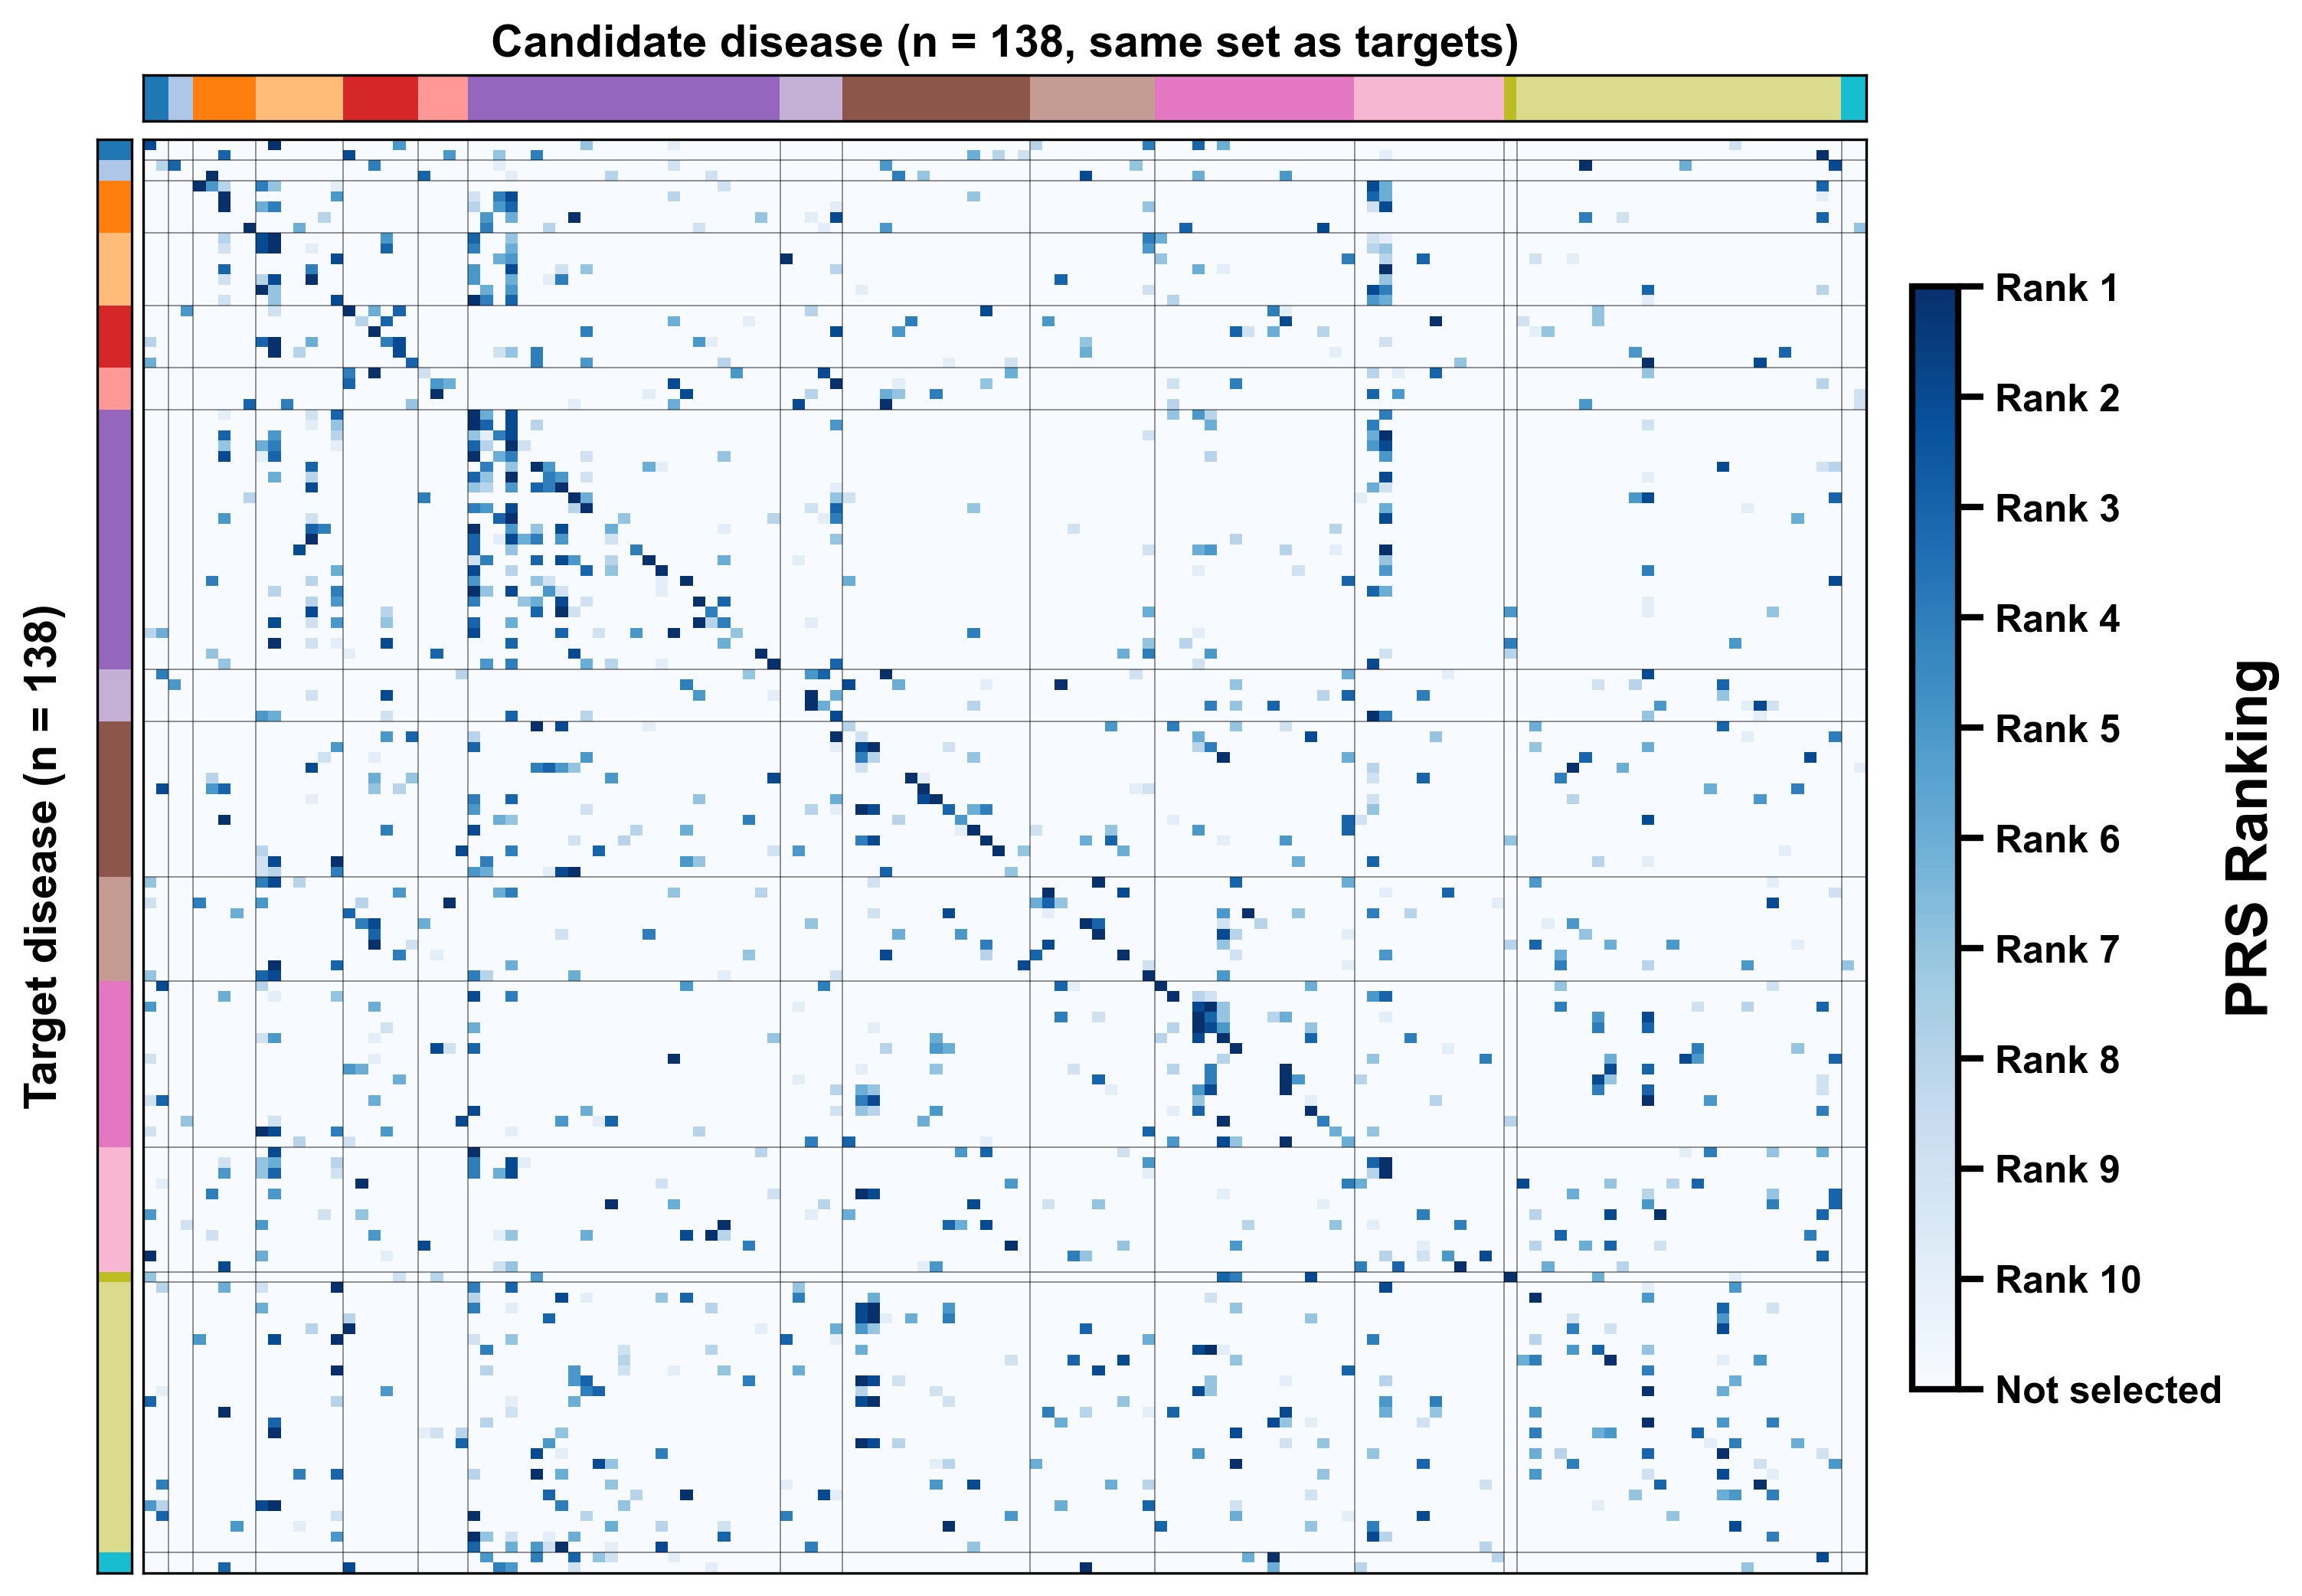

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import matplotlib
import seaborn as sns

matplotlib.rcParams["font.family"] = "Arial"

row_icd = list(afr_pmatrix.index)
col_icd = list(afr_pmatrix.columns)

row_chapters = [cm.assign_chapter(icd) for icd in row_icd]
col_chapters = [cm.assign_chapter(icd) for icd in col_icd]

row_colors = [cm.chapter2color_map.get(ch) for ch in row_chapters]
col_colors = [cm.chapter2color_map.get(ch) for ch in col_chapters]

# Figure layout
fig = plt.figure(figsize=(10, 8))

ax_colstrip = fig.add_axes([0.09, 0.91, 0.75, 0.025])
ax_rowstrip = fig.add_axes([0.07, 0.12, 0.015, 0.78])
ax_hm       = fig.add_axes([0.09, 0.12, 0.75, 0.78])
ax_cbar     = fig.add_axes([0.86, 0.22, 0.02, 0.60])

# Row chapter color strip
row_strip_array = np.array([mcolors.to_rgba(c) for c in row_colors]).reshape(len(row_icd), 1, 4)
ax_rowstrip.imshow(row_strip_array, aspect="auto", origin="upper")

ax_rowstrip.set_xticks([])
ax_rowstrip.set_yticks([])
ax_rowstrip.set_ylabel(f"Target disease (n = {len(row_icd)})", fontsize=14, fontweight="bold", labelpad=10)

# Column chapter color strip
col_strip_array = np.array([mcolors.to_rgba(c) for c in col_colors]).reshape(1, len(col_icd), 4)
ax_colstrip.imshow(col_strip_array, aspect="auto", origin="upper")

ax_colstrip.set_xticks([])
ax_colstrip.set_yticks([])
ax_colstrip.set_title(f"Candidate disease (n = {len(col_icd)}, same set as targets)", fontsize=14, fontweight="bold", pad=6)

# Heatmap
sns.heatmap(afr_pmatrix, cmap="Blues", vmin=0, vmax=10, ax=ax_hm, xticklabels=False, yticklabels=False, cbar=False)
ax_hm.set_xlabel("")
ax_hm.set_ylabel("")

for _, spine in ax_hm.spines.items():
    spine.set_visible(True)
    spine.set_linewidth(0.8)

# Chapter boundaries
row_boundaries = [i for i in range(1, len(row_chapters)) if row_chapters[i] != row_chapters[i - 1]]
col_boundaries = [i for i in range(1, len(col_chapters)) if col_chapters[i] != col_chapters[i - 1]]

for b in row_boundaries:
    ax_hm.axhline(b, color="black", linewidth=0.4, alpha=0.5)

for b in col_boundaries:
    ax_hm.axvline(b, color="black", linewidth=0.4, alpha=0.5)

# Colorbar
sm = plt.cm.ScalarMappable(cmap="Blues", norm=plt.Normalize(vmin=0, vmax=10))
sm.set_array([])

cbar = fig.colorbar(sm, cax=ax_cbar, ticks=list(range(11)))
cbar.set_ticklabels(["Not selected"] + [f"Rank {11 - v}" for v in range(1, 11)])
cbar.set_label("PRS Ranking", fontsize=18, fontweight="bold", labelpad=1)
cbar.outline.set_linewidth(2)
cbar.ax.tick_params(width=2, length=8)

for spine in cbar.ax.spines.values():
    spine.set_linewidth(2)
for label in cbar.ax.get_yticklabels():
    label.set_fontweight("bold")
    label.set_fontsize(12)

plt.show()